# FMCG Global Demand Planning and Forecasting: Capstone

**Data Science Cohort 7 | Time Series Analysis | 1.1M rows, 3 years of daily sales**

**Business problem.** Forecast error turns directly into money: overstock (inventory carrying cost) or stockouts (lost sales, service-level failures). This notebook quantifies the drivers of demand, builds a forecast that beats a naive planner, and translates forecast accuracy into safety-stock decisions, while auditing the model for fairness towards small local retailers.

**Pipeline:** SQL retrieval -> cleaning -> EDA and ABC/XYZ -> hypothesis tests -> feature engineering -> forecasting -> explainability and ethics -> recommendations.

**Project layout:** this notebook is the single narrative; reusable logic lives in `src/` (`config`, `data_prep`, `segmentation`, `features`, `models`, `evaluate`).

## Step 0: Setup

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, warnings
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config, data_prep, segmentation, features, evaluate
from src import models as models_mod

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")

In [2]:
# Peek at the first rows without loading the whole 200 MB file
sample = pd.read_csv(config.CSV_PATH, nrows=5)
sample

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,store_id,country,city,channel,latitude,longitude,sku_id,sku_name,category,subcategory,brand,units_sold,list_price,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.440,1.240,STORE0001,Germany,Berlin,Hypermarket,52.526,13.391,SKU0086,BrandB Shampoo,Personal Care,Shampoo,BrandB,16,10.490,0.100,1,167.840,151.060,248,0,11,S008,7.530,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.610,1.120,STORE0001,Germany,Berlin,Hypermarket,52.526,13.391,SKU0086,BrandB Shampoo,Personal Care,Shampoo,BrandB,12,10.490,0.000,0,125.880,125.880,238,0,6,S057,5.190,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.020,2.690,STORE0001,Germany,Berlin,Hypermarket,52.526,13.391,SKU0086,BrandB Shampoo,Personal Care,Shampoo,BrandB,38,10.490,0.300,1,398.620,279.030,238,0,6,S017,5.590,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.760,4.650,STORE0001,Germany,Berlin,Hypermarket,52.526,13.391,SKU0086,BrandB Shampoo,Personal Care,Shampoo,BrandB,8,10.490,0.000,0,83.920,83.920,216,0,7,S012,7.810,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.160,1.770,STORE0001,Germany,Berlin,Hypermarket,52.526,13.391,SKU0086,BrandB Shampoo,Personal Care,Shampoo,BrandB,17,10.490,0.200,1,178.330,142.660,372,0,8,S038,7.620,0.073


In [3]:
# Real column names and types: config.COLS maps our short names to these
sample.dtypes.to_frame("dtype").T

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,store_id,country,city,channel,latitude,longitude,sku_id,sku_name,category,subcategory,brand,units_sold,list_price,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
dtype,str,int64,int64,int64,int64,int64,int64,int64,float64,float64,str,str,str,str,float64,float64,str,str,str,str,str,int64,float64,float64,int64,float64,float64,int64,int64,int64,str,float64,float64


## Step 1: Data preparation and SQL retrieval

The CSV is streamed into a SQLite database in chunks (low memory) and indexed. From here on we pull data with SQL, selecting only the columns we need. The grain of this dataset is **store x SKU x day**.

In [4]:
data_prep.build_database()   # skipped automatically if fmcg.db already exists

WindowsPath('C:/Users/PC/Desktop/learning/data_ladder/dsatascience/capstone/fmcg.db')

In [5]:
# Guard: every column named in config.COLS must exist in the table
data_prep.check_columns()
print("All configured columns exist in the table.")

All configured columns exist in the table.


In [6]:
# SQL sanity check: size and coverage of the table
data_prep.run_query(f'''
    SELECT COUNT(*)                   AS n_rows,
           MIN("date")                AS first_day,
           MAX("date")                AS last_day,
           COUNT(DISTINCT "sku_id")   AS n_skus,
           COUNT(DISTINCT "store_id") AS n_stores,
           COUNT(DISTINCT "country")  AS n_countries,
           COUNT(DISTINCT "city")     AS n_cities,
           COUNT(DISTINCT "channel")  AS n_channels
    FROM {config.TABLE}''')

,n_rows,first_day,last_day,n_skus,n_stores,n_countries,n_cities,n_channels
0,1100000,2021-01-01,2023-12-31,102,13,7,9,4


In [7]:
# SQL filtering + aggregation: 2023 revenue by country and channel
data_prep.run_query(f'''
    SELECT "country", "channel",
           SUM("units_sold")           AS units,
           ROUND(SUM("net_sales"), 0)  AS revenue
    FROM {config.TABLE}
    WHERE "date" >= '2023-01-01'
    GROUP BY "country", "channel"
    ORDER BY revenue DESC
    LIMIT 15''')

,country,channel,units,revenue
0,Germany,Hypermarket,3912395,"29,494,670.000"
1,Spain,E-commerce,3510146,"25,547,275.000"
2,Italy,Supermarket,2755947,"19,681,768.000"
3,Austria,Hypermarket,1905515,"14,299,697.000"
4,France,Hypermarket,2004984,"14,195,261.000"
5,Poland,Hypermarket,1951425,"14,113,193.000"
6,Italy,Hypermarket,1993685,"14,043,947.000"
7,Italy,E-commerce,1704938,"12,020,055.000"
8,Spain,Supermarket,1374541,"9,994,738.000"
9,Netherlands,Convenience,575417,"4,179,471.000"


In [8]:
# SQL JOIN: sales joined to a geographic dimension (city coordinates) built with a CTE
data_prep.run_query(f'''
    WITH geo AS (
        SELECT "city", AVG("latitude") AS lat, AVG("longitude") AS lon
        FROM {config.TABLE} GROUP BY "city"
    )
    SELECT s."country", s."city", ROUND(g.lat, 2) AS lat, ROUND(g.lon, 2) AS lon,
           s."promo_flag", COUNT(*) AS n_rows,
           SUM(s."units_sold") AS units, ROUND(SUM(s."net_sales"), 0) AS revenue
    FROM {config.TABLE} s
    JOIN geo g ON s."city" = g."city"
    WHERE s."date" >= '2023-01-01'
    GROUP BY s."country", s."city", g.lat, g.lon, s."promo_flag"
    ORDER BY revenue DESC
    LIMIT 12''')

,country,city,lat,lon,promo_flag,n_rows,units,revenue
0,Germany,Berlin,52.510,13.410,0,53740,3358044,"26,387,640.000"
1,Italy,Rome,41.920,12.510,0,53928,2944081,"21,629,913.000"
2,Spain,Barcelona,41.380,2.180,0,53894,2691375,"20,150,243.000"
3,Italy,Milan,45.450,9.200,0,53817,2619585,"19,345,226.000"
4,Austria,Vienna,48.200,16.360,0,27071,1659546,"12,917,340.000"
5,France,Paris,48.880,2.360,0,26818,1714662,"12,747,298.000"
6,Poland,Warsaw,52.250,21.000,0,26758,1673189,"12,518,507.000"
7,Spain,Madrid,40.420,-3.670,0,26990,1517435,"11,803,703.000"
8,Netherlands,Amsterdam,52.360,4.960,0,14663,478038,"3,672,851.000"
9,Germany,Berlin,52.510,13.410,1,4660,554351,"3,107,030.000"


In [9]:
# Retrieve only the necessary columns, renamed to our short canonical names
raw = data_prep.load_sales()
print(raw.shape)
raw.head()

(1100000, 20)


,date,store,sku,sku_name,category,country,city,channel,lat,lon,volume,list_price,discount,promo,revenue,stock_on_hand,stockout,lead_time,is_holiday,is_weekend
0,2021-01-01,STORE0001,SKU0086,BrandB Shampoo,Personal Care,Germany,Berlin,Hypermarket,52.526,13.391,16,10.490,0.100,1,151.060,248,0,11,1,0
1,2021-01-02,STORE0001,SKU0086,BrandB Shampoo,Personal Care,Germany,Berlin,Hypermarket,52.526,13.391,12,10.490,0.000,0,125.880,238,0,6,0,1
2,2021-01-03,STORE0001,SKU0086,BrandB Shampoo,Personal Care,Germany,Berlin,Hypermarket,52.526,13.391,38,10.490,0.300,1,279.030,238,0,6,0,1
3,2021-01-04,STORE0001,SKU0086,BrandB Shampoo,Personal Care,Germany,Berlin,Hypermarket,52.526,13.391,8,10.490,0.000,0,83.920,216,0,7,0,0
4,2021-01-05,STORE0001,SKU0086,BrandB Shampoo,Personal Care,Germany,Berlin,Hypermarket,52.526,13.391,17,10.490,0.200,1,142.660,372,0,8,0,0


In [10]:
# Data-quality audit 1: types and nulls
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                      "nulls": raw.isna().sum(),
                      "null_%": (raw.isna().mean() * 100).round(2)})
audit

,dtype,nulls,null_%
date,str,0,0.000
store,str,0,0.000
sku,str,0,0.000
sku_name,str,0,0.000
category,str,0,0.000
country,str,0,0.000
city,str,0,0.000
channel,str,0,0.000
lat,float64,0,0.000
lon,float64,0,0.000


In [11]:
# Data-quality audit 2: duplicates, labels, value ranges
print("Duplicates on the true grain (date, store, sku):", raw.duplicated(["date", "store", "sku"]).sum())
print("Rows sharing the guide's key (date, sku, channel, city):", raw.duplicated(["date", "sku", "channel", "city"]).sum())
print("Stores:", raw["store"].nunique(), "| Channels:", sorted(raw["channel"].unique()))
raw[["volume", "list_price", "discount", "lead_time", "stock_on_hand"]].describe().T

Duplicates on the true grain (date, store, sku): 0
Rows sharing the guide's key (date, sku, channel, city): 67890
Stores: 13 | Channels: ['Convenience', 'E-commerce', 'Hypermarket', 'Supermarket']


,count,mean,std,min,25%,50%,75%,max
volume,"1,100,000.000",59.196,45.007,0.000,25.000,49.000,82.000,704.000
list_price,"1,100,000.000",7.712,4.253,1.080,4.200,7.380,11.650,14.800
discount,"1,100,000.000",0.015,0.055,0.000,0.000,0.000,0.000,0.300
lead_time,"1,100,000.000",6.500,2.014,1.000,5.000,6.000,8.000,17.000
stock_on_hand,"1,100,000.000",299.476,80.073,0.000,245.000,300.000,354.000,698.000


**Note on uniqueness.** A city holds several stores per channel, so the guide's key (SKU-Date-Channel-City) is not unique in this dataset. The true unique key is **date + store + SKU**, and that is what deduplication uses. Collapsing on the guide's key would silently delete real sales.

In [12]:
# Clean: parse dates, impute coordinates and lead time (median), standardise labels, drop invalid rows and duplicates
df, report = data_prep.clean(raw)
display(pd.Series(report, name="value").to_frame())
print("Channels after standardisation:", sorted(df["channel"].unique()))
print("Nulls remaining:", int(df.isna().sum().sum()))
del raw

,value
rows_in,1100000
rows_dropped_missing_core,0
rows_dropped_invalid,0
duplicates_removed,0
rows_sharing_guide_key,67890
rows_out,1100000


Channels after standardisation: ['Convenience', 'E-commerce', 'Hypermarket', 'Supermarket']
Nulls remaining: 0


In [13]:
# Left join to the promotional calendar (date x SKU x country): every sales row keeps its place and is flagged
calendar = data_prep.build_promo_calendar(df)
df = data_prep.merge_promo(df, calendar)
display(calendar.head())
pd.crosstab(df["promo"], df["promo_active_country"], margins=True)

,date,sku,country,promo_active_country,avg_discount_country
0,2021-01-01,SKU0001,Austria,0,0.000
1,2021-01-01,SKU0001,France,0,0.000
2,2021-01-01,SKU0001,Germany,0,0.000
3,2021-01-01,SKU0001,Italy,0,0.000
4,2021-01-01,SKU0001,Netherlands,0,0.000


promo_active_country,0,1,All
promo,,,
0,1011743,0,1011743
1,0,88257,88257
All,1011743,88257,1100000


In [14]:
# Checkpoint so later sessions can skip Step 1 above
df.to_parquet(config.CLEAN_PATH, index=False)
# later sessions: df = pd.read_parquet(config.CLEAN_PATH)
print(df.shape, df["date"].min().date(), "->", df["date"].max().date())

(1100000, 25) 2021-01-01 -> 2023-12-31


In [15]:
# Dataset at a glance (for the slides)
overview = pd.Series({
    "rows": f"{len(df):,}", "SKUs": df["sku"].nunique(), "stores": df["store"].nunique(),
    "countries": df["country"].nunique(), "cities": df["city"].nunique(),
    "channels": df["channel"].nunique(), "days": df["date"].nunique(),
    "promo share of rows": f"{df['promo'].mean():.1%}", "stockout rate": f"{df['stockout'].mean():.2%}"},
    name="dataset")
overview.to_frame()

,dataset
rows,"1,100,000"
SKUs,102
stores,13
countries,7
cities,9
channels,4
days,1095
promo share of rows,8.0%
stockout rate,3.01%


## Step 2: Exploratory data analysis and market dynamics

In [16]:
# Statistical baseline: mean, median, std of units sold
df["volume"].agg(["count", "mean", "median", "std", "min", "max"]).to_frame("units_sold")

,units_sold
count,"1,100,000.000"
mean,59.196
median,49.000
std,45.007
min,0.000
max,704.000


In [17]:
# Baseline by channel with coefficient of variation (CV = std / mean)
by_channel = df.groupby("channel")["volume"].agg(["mean", "median", "std"])
by_channel["cv"] = by_channel["std"] / by_channel["mean"]
by_channel.sort_values("cv", ascending=False)

,mean,median,std,cv
channel,,,,
Convenience,35.457,29.000,27.309,0.770
Supermarket,47.170,39.000,35.037,0.743
Hypermarket,67.240,57.000,49.205,0.732
E-commerce,59.543,50.000,43.492,0.730


In [18]:
# Which regions have the most volatile demand? CV at store-SKU-day level and for daily country totals
row_cv = df.groupby("country")["volume"].agg(mean="mean", median="median", std="std")
row_cv["cv_row_level"] = row_cv["std"] / row_cv["mean"]
daily_country = df.groupby(["country", "date"])["volume"].sum().reset_index()
tot = daily_country.groupby("country")["volume"].agg(["mean", "std"])
row_cv["cv_daily_total"] = tot["std"] / tot["mean"]
cv_country = row_cv.sort_values("cv_daily_total", ascending=False)
cv_country.round(3)

,mean,median,std,cv_row_level,cv_daily_total
country,,,,,
Netherlands,35.457,29.000,27.309,0.770,0.124
Austria,65.550,55.000,47.932,0.731,0.113
France,68.664,57.000,50.602,0.737,0.113
Poland,66.897,56.000,49.069,0.734,0.111
Germany,67.001,57.000,48.848,0.729,0.106
Italy,55.256,46.000,42.287,0.765,0.106
Spain,55.814,47.000,41.265,0.739,0.104


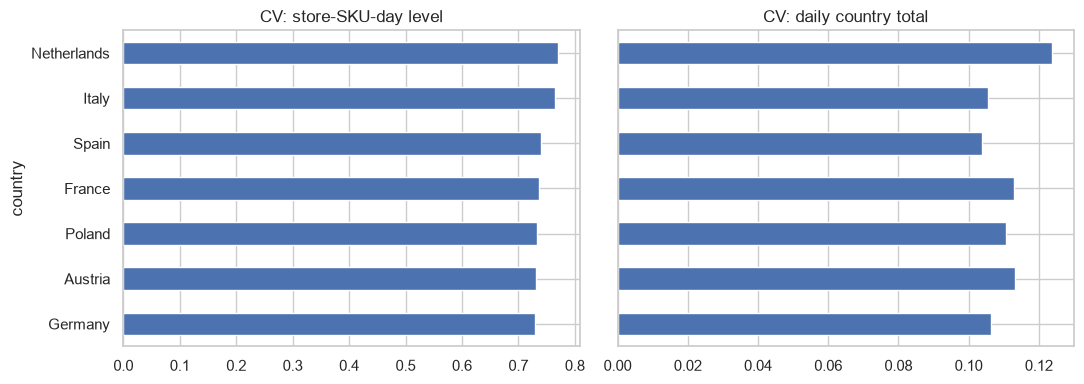

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
cv_country["cv_row_level"].sort_values().plot.barh(ax=ax[0], title="CV: store-SKU-day level")
cv_country["cv_daily_total"].reindex(cv_country["cv_row_level"].sort_values().index).plot.barh(ax=ax[1], title="CV: daily country total")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "cv_by_country.png", dpi=150)
plt.show()

In [20]:
# City-level logistics table. "Logistics desert" = high demand AND high lead-time variability (both above the median)
city = (df.groupby(["city", "country"])
          .agg(volume=("volume", "sum"), revenue=("revenue", "sum"),
               lat=("lat", "mean"), lon=("lon", "mean"),
               lt_mean=("lead_time", "mean"), lt_std=("lead_time", "std"),
               stockout=("stockout", "mean"))
          .reset_index())
city["logistics_desert"] = ((city["volume"] >= city["volume"].median()) &
                            (city["lt_std"] >= city["lt_std"].median()))
city.sort_values("volume", ascending=False).round(3)

,city,country,volume,revenue,lat,lon,lt_mean,lt_std,stockout,logistics_desert
2,Berlin,Germany,11738571,"88,525,559.010",52.513,13.406,6.505,2.012,0.030,False
6,Rome,Italy,10235360,"72,437,522.630",41.924,12.509,6.498,2.013,0.030,False
1,Barcelona,Spain,9424679,"67,739,349.270",41.384,2.184,6.496,2.015,0.029,True
4,Milan,Italy,9126414,"64,755,553.490",45.452,9.200,6.496,2.011,0.030,False
5,Paris,France,6014974,"42,601,612.570",48.876,2.360,6.500,2.016,0.031,True
8,Warsaw,Poland,5860180,"42,385,262.520",52.253,20.996,6.506,2.016,0.030,False
7,Vienna,Austria,5742174,"43,020,025.970",48.203,16.359,6.494,2.008,0.031,False
3,Madrid,Spain,5243338,"38,965,417.770",40.417,-3.675,6.512,2.019,0.031,False
0,Amsterdam,Netherlands,1730292,"12,516,149.600",52.362,4.958,6.508,2.032,0.030,False


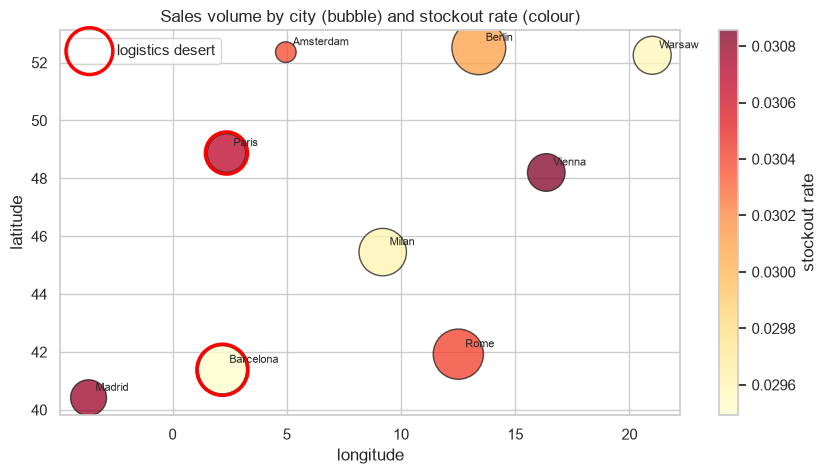

In [21]:
# Static map of sales density (always renders): bubble = volume, colour = stockout rate, red ring = logistics desert
fig, ax = plt.subplots(figsize=(10, 5))
sc = ax.scatter(city["lon"], city["lat"], s=city["volume"] / city["volume"].max() * 1500,
                c=city["stockout"], cmap="YlOrRd", alpha=0.75, edgecolor="k")
d = city[city["logistics_desert"]]
ax.scatter(d["lon"], d["lat"], s=d["volume"] / city["volume"].max() * 1500 + 150,
           facecolors="none", edgecolors="red", linewidths=2.5, label="logistics desert")
for _, r in city.iterrows():
    ax.annotate(r["city"], (r["lon"], r["lat"]), fontsize=8, xytext=(5, 5), textcoords="offset points")
plt.colorbar(sc, label="stockout rate")
ax.set(xlabel="longitude", ylabel="latitude", title="Sales volume by city (bubble) and stockout rate (colour)")
ax.legend()
plt.savefig(config.FIG_DIR / "sales_map_static.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
# Interactive heat map (also saved as HTML for the portfolio)
import folium
from folium.plugins import HeatMap

m = folium.Map(location=[city["lat"].mean(), city["lon"].mean()], zoom_start=3)
HeatMap(city[["lat", "lon", "volume"]].values.tolist(), radius=30, blur=20).add_to(m)
for _, r in city[city["logistics_desert"]].iterrows():
    folium.CircleMarker([r["lat"], r["lon"]], radius=8, color="red", fill=True,
                        tooltip=f"{r['city']}: logistics desert").add_to(m)
m.save(config.FIG_DIR / "sales_heatmap.html")
m

Stores: 13 | Spearman rho (lead-time std vs stockout rate) = 0.110, p = 0.7208


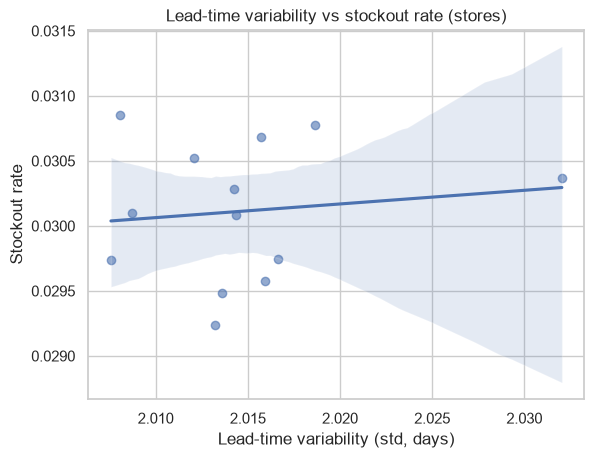

In [23]:
# Lead-time variability vs stockouts, store level
from scipy.stats import spearmanr

store = (df.groupby(["store", "city"])
           .agg(lt_std=("lead_time", "std"), lt_mean=("lead_time", "mean"),
                stockout=("stockout", "mean"), volume=("volume", "sum"))
           .reset_index())
rho, p = spearmanr(store["lt_std"], store["stockout"])
print(f"Stores: {len(store)} | Spearman rho (lead-time std vs stockout rate) = {rho:.3f}, p = {p:.4f}")

sns.regplot(data=store, x="lt_std", y="stockout", scatter_kws={"alpha": .6})
plt.xlabel("Lead-time variability (std, days)")
plt.ylabel("Stockout rate")
plt.title("Lead-time variability vs stockout rate (stores)")
plt.savefig(config.FIG_DIR / "leadtime_vs_stockout.png", dpi=150)
plt.show()

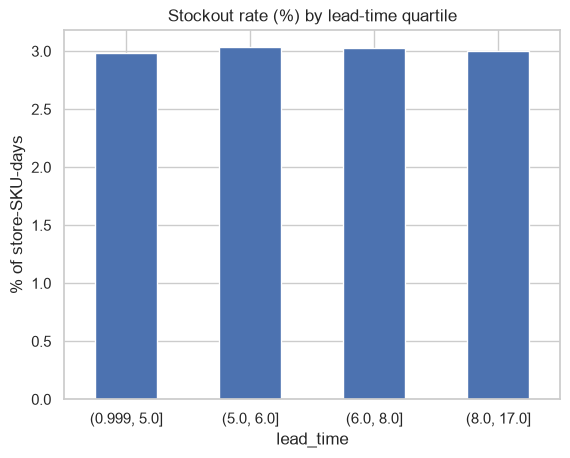

,stockout_%
lead_time,
"(0.999, 5.0]",2.990
"(5.0, 6.0]",3.030
"(6.0, 8.0]",3.020
"(8.0, 17.0]",3.000


In [24]:
# Same question at row level: stockout rate by lead-time quartile
bucket = pd.qcut(df["lead_time"], 4, duplicates="drop")
by_lt = df.groupby(bucket, observed=True)["stockout"].mean() * 100
by_lt.index = by_lt.index.astype(str)
by_lt.plot.bar(rot=0, title="Stockout rate (%) by lead-time quartile", ylabel="% of store-SKU-days")
plt.savefig(config.FIG_DIR / "stockout_by_leadtime_quartile.png", dpi=150)
plt.show()
by_lt.round(2).to_frame("stockout_%")

In [25]:
# ABC analysis by revenue: A = top 80%, B = next 15%, C = last 5%
abc = segmentation.abc_analysis(df, "sku")
summary = abc.groupby("abc").agg(n_skus=("sku", "count"), revenue_share=("share", "sum"))
summary

,n_skus,revenue_share
abc,,
A,50,0.801
B,29,0.153
C,23,0.047


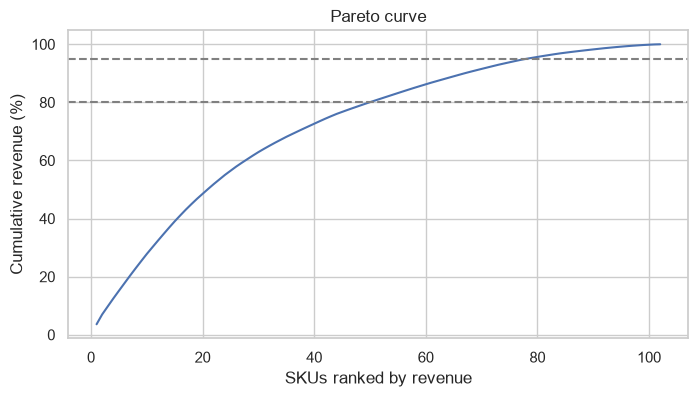

In [26]:
# Pareto curve of SKU revenue
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(abc) + 1), abc["cum_share"] * 100)
plt.axhline(80, ls="--", c="grey"); plt.axhline(95, ls="--", c="grey")
plt.xlabel("SKUs ranked by revenue"); plt.ylabel("Cumulative revenue (%)"); plt.title("Pareto curve")
plt.savefig(config.FIG_DIR / "pareto.png", dpi=150)
plt.show()

In [27]:
# XYZ analysis by demand volatility: CV of monthly volume per SKU
monthly = df.groupby(["sku", "year", "month"])["volume"].sum().reset_index()
xyz, xyz_info = segmentation.xyz_analysis(monthly, "sku", "volume")
print("XYZ cut-offs used:", xyz_info)
xyz["xyz"].value_counts().reindex(["X", "Y", "Z"]).to_frame("n_skus")

XYZ cut-offs used: {'method': 'terciles', 'x_cut': 0.044, 'y_cut': 0.117}


,n_skus
xyz,
X,34
Y,34
Z,34


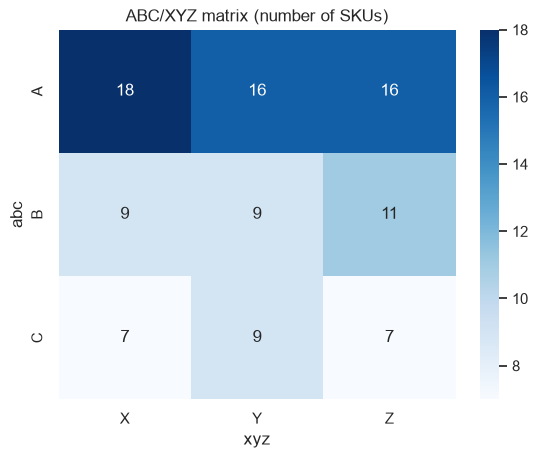

In [28]:
# Combined ABC/XYZ segment per SKU
seg = abc.merge(xyz[["sku", "cv", "xyz"]], on="sku")
seg["segment"] = seg["abc"] + seg["xyz"]
seg["n_obs"] = seg["sku"].map(df["sku"].value_counts())
matrix = pd.crosstab(seg["abc"], seg["xyz"])
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues")
plt.title("ABC/XYZ matrix (number of SKUs)")
plt.savefig(config.FIG_DIR / "abc_xyz_matrix.png", dpi=150)
plt.show()

In [29]:
# Regional comparison: are A-products in one country C-products in another?
abc_region = segmentation.abc_by_region(df, "country", "sku")
pivot = abc_region.pivot(index="sku", columns="country", values="abc")
mixed = pivot[(pivot == "A").any(axis=1) & (pivot == "C").any(axis=1)]
print(f"{len(mixed)} of {len(pivot)} SKUs are A-products in at least one country and C-products in another")
pd.crosstab(abc_region["country"], abc_region["abc"], normalize="index").round(3)

6 of 102 SKUs are A-products in at least one country and C-products in another


abc,A,B,C
country,,,
Austria,0.488,0.288,0.225
France,0.475,0.288,0.238
Germany,0.459,0.286,0.255
Italy,0.490,0.284,0.225
Netherlands,0.489,0.289,0.222
Poland,0.500,0.288,0.212
Spain,0.470,0.290,0.240


In [30]:
mixed.head(10)

country,Austria,France,Germany,Italy,Netherlands,Poland,Spain
sku,,,,,,,
SKU0014,B,NaN,B,A,B,B,C
SKU0043,B,NaN,C,A,NaN,B,B
SKU0049,A,NaN,A,C,A,A,A
SKU0072,A,B,A,C,NaN,B,A
SKU0080,A,NaN,B,C,A,A,A
SKU0088,B,B,C,A,NaN,B,B


In [31]:
# Select the 10 representative SKUs across demand profiles (AX, AY, BY, CZ, ...)
sel = segmentation.select_skus(seg)
names = df.drop_duplicates("sku").set_index("sku")[["sku_name", "category"]]
sel = sel.merge(names, left_on="sku", right_index=True)
sel_skus = sel["sku"].tolist()
sel[["sku", "sku_name", "category", "segment", "revenue", "cv", "n_obs"]]

,sku,sku_name,category,segment,revenue,cv,n_obs
0,SKU0092,BrandB Soap,Personal Care,AX,"12,496,995.900",0.040,9855
1,SKU0100,BrandD Toothpaste,Personal Care,AX,"12,351,150.680",0.031,10950
2,SKU0027,BrandC Chips,Snacks,AY,"16,000,295.020",0.100,10950
3,SKU0026,BrandB Chips,Snacks,AY,"13,025,419.730",0.111,10950
4,SKU0090,BrandF Shampoo,Personal Care,BX,"2,963,734.950",0.035,10950
5,SKU0046,BrandD Nuts,Snacks,BY,"2,769,564.710",0.108,12045
6,SKU0066,BrandF Cheese,Dairy,BY,"2,555,968.460",0.077,12045
7,SKU0040,BrandD Biscuits,Snacks,CY,"1,430,335.280",0.108,12045
8,SKU0022,BrandD Energy drink,Beverages,CZ,"1,513,665.560",0.204,9855
9,SKU0015,BrandC Water,Beverages,CZ,"1,435,332.870",0.204,13140


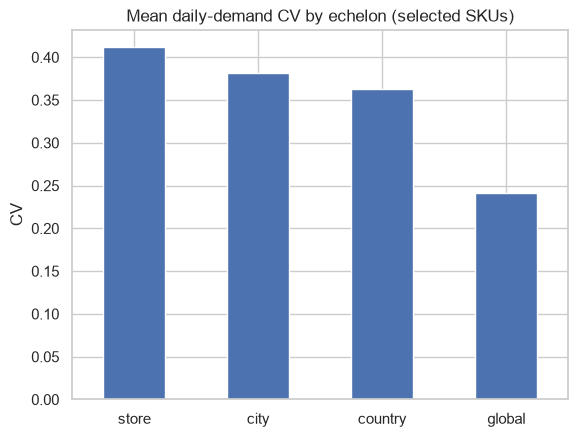

,store,city,country,global
mean_cv,0.411,0.381,0.363,0.241


In [32]:
# Demand variability by echelon (store -> city -> country -> global) for the selected SKUs.
# The data holds sales, not orders, so a true bullwhip ratio is not computable; this shows the
# variability that safety stock must absorb at each level (risk pooling).
sub = df[df["sku"].isin(sel_skus)]
levels = {"store": ["store"], "city": ["city"], "country": ["country"], "global": []}
out = {}
for name, lvl in levels.items():
    t = sub.groupby(["date", "sku"] + lvl)["volume"].sum().reset_index()
    g = t.groupby(["sku"] + lvl)["volume"].agg(["mean", "std"])
    out[name] = (g["std"] / g["mean"]).groupby(level="sku").mean()
echelon = pd.DataFrame(out)
echelon.mean().plot.bar(rot=0, title="Mean daily-demand CV by echelon (selected SKUs)", ylabel="CV")
plt.savefig(config.FIG_DIR / "echelon_cv.png", dpi=150)
plt.show()
echelon.mean().to_frame("mean_cv").T

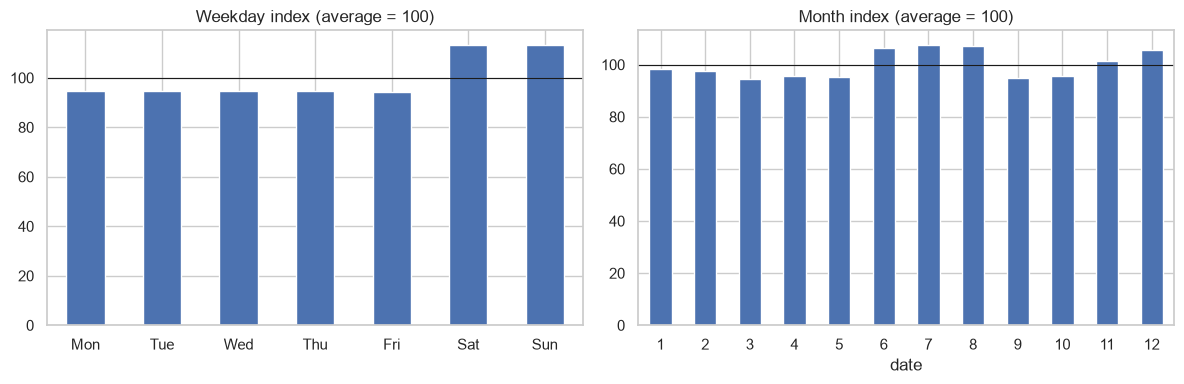

Weekday swing: Fri 94 to Sun 113
Month swing: month 3 95 to month 7 108
Holiday days vs other days: +6.1% total demand


In [33]:
# Seasonality 1: weekday and month profiles of total daily demand (average day = 100)
daily = df.groupby("date")["volume"].sum()
dow_idx = daily.groupby(daily.index.dayofweek).mean() / daily.mean() * 100
dow_idx.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
mon_idx = daily.groupby(daily.index.month).mean() / daily.mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dow_idx.plot.bar(ax=ax[0], rot=0, title="Weekday index (average = 100)")
mon_idx.plot.bar(ax=ax[1], rot=0, title="Month index (average = 100)")
for a in ax:
    a.axhline(100, c="k", lw=0.8)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "seasonality_profiles.png", dpi=150)
plt.show()

hs = df.groupby("date")["is_holiday"].mean()
hol_effect = (daily[hs > 0].mean() / daily[hs == 0].mean() - 1) * 100 if (hs > 0).any() else float("nan")
print(f"Weekday swing: {dow_idx.idxmin()} {dow_idx.min():.0f} to {dow_idx.idxmax()} {dow_idx.max():.0f}")
print(f"Month swing: month {mon_idx.idxmin()} {mon_idx.min():.0f} to month {mon_idx.idxmax()} {mon_idx.max():.0f}")
print(f"Holiday days vs other days: {hol_effect:+.1f}% total demand")

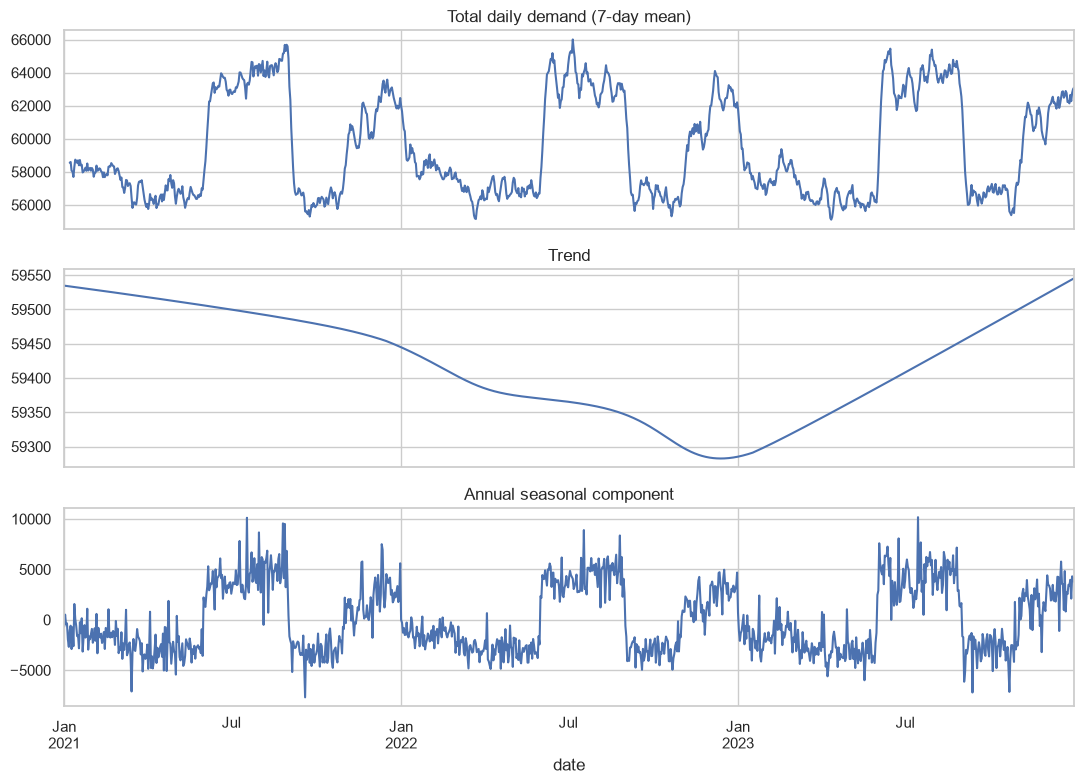

,seasonal_strength
weekly,0.924
annual,0.885


In [34]:
# Seasonality 2: STL decomposition and seasonal strength (0 = none, 1 = pure seasonality; above 0.64 is strong)
from statsmodels.tsa.seasonal import STL

daily = daily.asfreq("D")

def strength(res):
    return max(0.0, 1 - res.resid.var() / (res.seasonal + res.resid).var())

stl_w = STL(daily, period=7, robust=True).fit()                 # weekly cycle
stl_y = STL(daily - stl_w.seasonal, period=365, robust=True).fit()   # annual cycle after removing the weekly one
season_strength = pd.Series({"weekly": strength(stl_w), "annual": strength(stl_y)}, name="seasonal_strength")

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
daily.rolling(7).mean().plot(ax=ax[0], title="Total daily demand (7-day mean)")
stl_y.trend.plot(ax=ax[1], title="Trend")
stl_y.seasonal.plot(ax=ax[2], title="Annual seasonal component")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "stl_decomposition.png", dpi=150)
plt.show()
season_strength.round(3).to_frame()

## Step 3: Statistical rigor and hypothesis testing

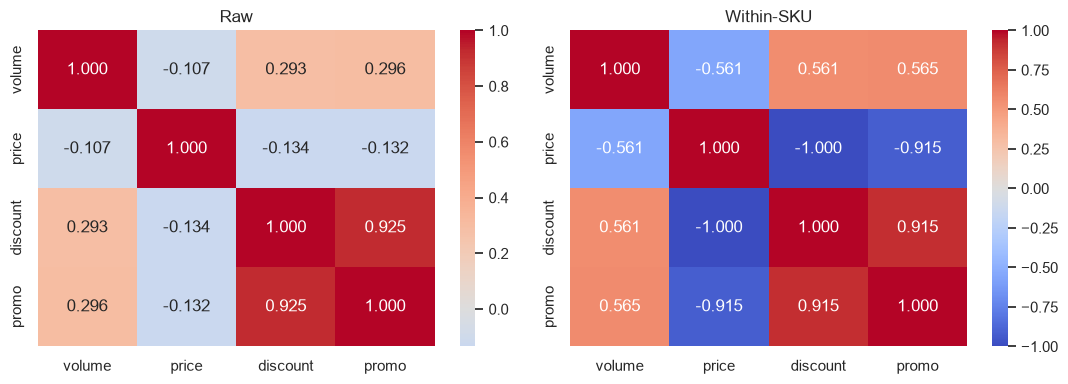

In [35]:
# Correlation matrix between volume, price, discount and promotion.
# Left: raw (mixes cheap and expensive SKUs). Right: within-SKU (each SKU standardised), the fair comparison.
cols = ["volume", "price", "discount", "promo"]
grp = df.groupby("sku")[cols]
within = (df[cols] - grp.transform("mean")) / grp.transform("std")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(df[cols].corr(), annot=True, fmt=".3f", cmap="coolwarm", center=0, ax=ax[0]); ax[0].set_title("Raw")
sns.heatmap(within.corr(), annot=True, fmt=".3f", cmap="coolwarm", center=0, ax=ax[1]); ax[1].set_title("Within-SKU")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "correlation.png", dpi=150)
plt.show()

In [36]:
# Baseline-adjusted demand: units relative to that store-SKU's own average, so promo comparisons are not confounded by SKU mix
df["vol_index"] = df["volume"] / df.groupby(["store", "sku"])["volume"].transform("mean")

In [37]:
# Promotional lift. H0: promo mean <= non-promo mean. H1: promo mean > non-promo mean. alpha = 0.05
from scipy import stats

def promo_test(col):
    a = df.loc[df["promo"] == 1, col]
    b = df.loc[df["promo"] == 0, col]
    u = stats.mannwhitneyu(a, b, alternative="greater")
    t = stats.ttest_ind(a, b, equal_var=False, alternative="greater")
    d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    return {"metric": col, "promo_mean": a.mean(), "base_mean": b.mean(),
            "lift_%": (a.mean() / b.mean() - 1) * 100, "MannWhitney_p": u.pvalue,
            "Welch_t_p": t.pvalue, "cohen_d": d}

promo_results = pd.DataFrame([promo_test("volume"), promo_test("vol_index")]).set_index("metric")
lift_raw = promo_results.loc["volume", "lift_%"]
lift_adj = promo_results.loc["vol_index", "lift_%"]
display(promo_results.round(4))
print("Decision (alpha = 0.05):", "reject H0, promotions increase volume" if promo_results["MannWhitney_p"].max() < 0.05 else "fail to reject H0 for at least one metric")

,promo_mean,base_mean,lift_%,MannWhitney_p,Welch_t_p,cohen_d
metric,,,,,,
volume,104.268,55.265,88.669,0.000,0.000,0.830
vol_index,1.590,0.949,67.635,0.000,0.000,1.291


Decision (alpha = 0.05): reject H0, promotions increase volume


In [38]:
# Robustness: with 1M+ rows every p-value is tiny, so also check breadth. Do SKUs sell more on promo?
sku_means = df.groupby(["sku", "promo"])["volume"].mean().unstack().dropna()
w = stats.wilcoxon(sku_means[1], sku_means[0], alternative="greater")
share_up = (sku_means[1] > sku_means[0]).mean()
print(f"{share_up:.1%} of SKUs sell more on promotion | Wilcoxon signed-rank p = {w.pvalue:.2e}")

100.0% of SKUs sell more on promotion | Wilcoxon signed-rank p = 4.55e-13


In [39]:
# Price elasticity for A-category SKUs: log-log OLS, store and month fixed effects, robust errors.
# elasticity_total = response to the effective price (includes the promo effect);
# elasticity_ctrl  = same, controlling for the promo flag separately.
import statsmodels.formula.api as smf

a_skus = abc.loc[abc["abc"] == "A", "sku"]
rows = []
for sku, d in df[df["sku"].isin(a_skus) & (df["volume"] > 0)].groupby("sku"):
    d = d[["volume", "price", "promo", "store", "month"]].copy()
    if len(d) < 500 or d["price"].nunique() < 2:
        continue
    d["ln_v"], d["ln_p"] = np.log(d["volume"]), np.log(d["price"])
    m1 = smf.ols("ln_v ~ ln_p + C(store) + C(month)", d).fit(cov_type="HC1")
    m2 = smf.ols("ln_v ~ ln_p + promo + C(store) + C(month)", d).fit(cov_type="HC1")
    rows.append({"sku": sku, "elasticity_total": m1.params["ln_p"], "p_total": m1.pvalues["ln_p"],
                 "elasticity_ctrl": m2.params["ln_p"], "p_ctrl": m2.pvalues["ln_p"], "n": len(d)})

elas = pd.DataFrame(rows)
assert len(elas) > 0, "no A-SKU has enough price variation to estimate elasticity"
print(f"{len(elas)} A-SKUs modelled | median elasticity (total) = {elas['elasticity_total'].median():.3f} "
      f"| significant at 5%: {(elas['p_total'] < 0.05).mean():.0%}")
elas[["elasticity_total", "elasticity_ctrl"]].describe().round(3)

21 A-SKUs modelled | median elasticity (total) = -2.542 | significant at 5%: 100%


,elasticity_total,elasticity_ctrl
count,21.000,21.000
mean,-2.545,-0.855
std,0.067,0.147
min,-2.701,-1.038
25%,-2.565,-0.956
50%,-2.542,-0.898
75%,-2.492,-0.728
max,-2.462,-0.556


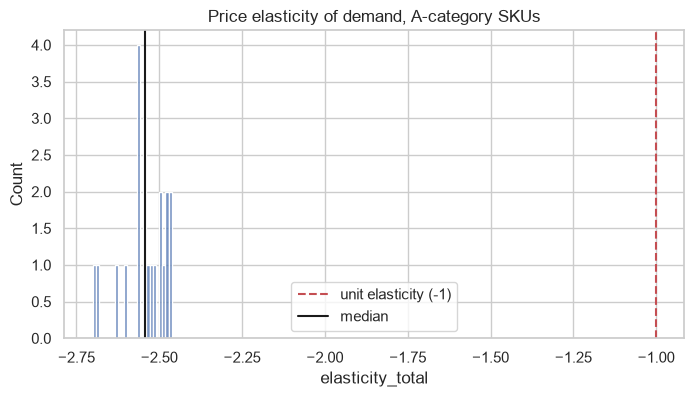

In [40]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(elas["elasticity_total"], bins=25, ax=ax)
ax.axvline(-1, ls="--", c="r", label="unit elasticity (-1)")
ax.axvline(elas["elasticity_total"].median(), c="k", label="median")
ax.set_title("Price elasticity of demand, A-category SKUs"); ax.legend()
plt.savefig(config.FIG_DIR / "elasticity.png", dpi=150)
plt.show()

**Sampling strategy.** Random shuffling is **not** used: it would let the model train on the future and destroy the temporal order. The hold-out set is the **last 6 months** of the data, training uses everything before it, and scalers are fit on the training set only.

## Step 4: Feature engineering and preprocessing

Features are built on a daily panel for the 10 selected SKUs. All lag and rolling features are shifted by at least one day, so each row only sees the past. Promotions, price and the calendar are known in advance in planning, so they are used for the same day.

In [41]:
# Daily SKU panel (missing days filled with 0 sales)
panel = features.build_panel(df, sel_skus)
print(panel.shape, "| zero-sales days:", f"{(panel['volume'] == 0).mean():.1%}")
panel.head()

(10950, 10) | zero-sales days: 0.0%


,sku,date,volume,revenue,promo,discount,lead_time,stockout_rate,price,holiday_share
0,SKU0015,2021-01-01,123,"1,142.670",0.000,0.000,6.583,0.000,9.290,1.000
1,SKU0015,2021-01-02,148,"1,374.920",0.000,0.000,5.500,0.000,9.290,0.000
2,SKU0015,2021-01-03,165,"1,532.850",0.000,0.000,5.750,0.000,9.290,0.000
3,SKU0015,2021-01-04,129,"1,198.410",0.000,0.000,6.000,0.000,9.290,0.000
4,SKU0015,2021-01-05,93,863.970,0.000,0.000,6.250,0.000,9.290,0.000


In [42]:
# Augmented Dickey-Fuller test per SKU, on the level and on the first difference
rows = []
for sku, g in panel.groupby("sku"):
    s = g.sort_values("date")["volume"]
    r0, r1 = features.adf_test(s), features.adf_test(s.diff())
    rows.append({"sku": sku, **{f"level_{k}": v for k, v in r0.items()},
                 **{f"diff1_{k}": v for k, v in r1.items()}})
adf_table = pd.DataFrame(rows)
adf_table

,sku,level_adf_stat,level_p_value,level_stationary,diff1_adf_stat,diff1_p_value,diff1_stationary
0,SKU0015,-3.133,0.024,True,-7.668,0.000,True
1,SKU0022,-3.095,0.027,True,-7.366,0.000,True
2,SKU0026,-2.805,0.058,False,-10.047,0.000,True
3,SKU0027,-8.280,0.000,True,-14.963,0.000,True
4,SKU0040,-3.953,0.002,True,-13.192,0.000,True
5,SKU0046,-6.783,0.000,True,-12.453,0.000,True
6,SKU0066,-7.695,0.000,True,-13.102,0.000,True
7,SKU0090,-7.177,0.000,True,-12.209,0.000,True
8,SKU0092,-6.748,0.000,True,-10.431,0.000,True
9,SKU0100,-6.452,0.000,True,-13.936,0.000,True


**Reading the ADF table.** `stationary = True` means the unit-root null is rejected (p < 0.05). Where the level series is non-stationary, first differencing makes it stationary (see the `diff1_` columns). The lag and rolling features carry that differenced signal into the models, and tree ensembles are insensitive to monotonic trends, so the target is modelled in units (interpretable for planners).

In [43]:
# Engineer features, then split by time (last 6 months = test)
panel_f = features.add_features(panel)
train, test, cutoff = features.time_split(panel_f)
assert train["date"].max() < test["date"].min(), "time leakage!"
print(f"Cutoff: {cutoff.date()} | train {len(train):,} rows ({train['date'].min().date()} -> {train['date'].max().date()})"
      f" | test {len(test):,} rows ({test['date'].min().date()} -> {test['date'].max().date()})")

Cutoff: 2023-06-30 | train 8,810 rows (2021-01-31 -> 2023-06-30) | test 1,840 rows (2023-07-01 -> 2023-12-31)


In [44]:
# Preprocessing: one-hot encode SKU; StandardScaler fitted on TRAIN only and applied to test
X_tr, X_te, X_tr_s, X_te_s, scaler = models_mod.make_matrices(train, test, features.NUM_FEATURES, ["sku"])
y_tr, y_te = train["volume"], test["volume"]
print(X_tr.shape, X_te.shape)

(8810, 28) (1840, 28)


## Step 5: Machine learning forecasting

Models: a **seasonal-naive baseline** (same weekday last week), **Linear Regression** (performance floor), **Random Forest** and **LightGBM** (non-linear drivers such as promo x seasonality).

In [45]:
# Train all models and score them on the hold-out period
preds = test[["date", "sku", "volume"]].copy()
preds["Naive (lag 7)"] = test["lag_7"].values
results = [{"model": "Naive (lag 7)", **evaluate.regression_metrics(y_te, preds["Naive (lag 7)"])}]
fitted = {}

for name, model in models_mod.get_models().items():
    Xa, Xb = (X_tr_s, X_te_s) if name == "Linear Regression" else (X_tr, X_te)
    model.fit(Xa, y_tr)
    preds[name] = np.clip(model.predict(Xb), 0, None)
    fitted[name] = model
    results.append({"model": name, **evaluate.regression_metrics(y_te, preds[name])})

pd.DataFrame(results).round(2)

,model,MAE,RMSE,MAPE_%,WAPE_%,Bias_%
0,Naive (lag 7),140.890,253.960,20.140,21.250,-0.350
1,Linear Regression,88.960,133.200,16.350,13.410,0.440
2,Random Forest,62.930,98.210,9.530,9.490,0.130
3,LightGBM,63.230,96.240,9.730,9.540,0.210


In [46]:
# Tune LightGBM with time-aware cross-validation (no shuffling)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from lightgbm import LGBMRegressor

param_dist = {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1],
              "num_leaves": [15, 31, 63], "min_child_samples": [10, 20, 40],
              "subsample": [0.7, 0.8, 1.0], "colsample_bytree": [0.6, 0.8, 1.0]}
search = RandomizedSearchCV(
    LGBMRegressor(random_state=config.RANDOM_STATE, subsample_freq=1, importance_type="gain", verbose=-1),
    param_dist, n_iter=15, cv=TimeSeriesSplit(4), scoring="neg_mean_absolute_error",
    n_jobs=1, random_state=config.RANDOM_STATE)
search.fit(X_tr, y_tr)
print(search.best_params_)

{'subsample': 0.7, 'num_leaves': 15, 'n_estimators': 300, 'min_child_samples': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.6}


In [47]:
# Score the tuned model and rank everything
best = search.best_estimator_
fitted["LightGBM (tuned)"] = best
preds["LightGBM (tuned)"] = np.clip(best.predict(X_te), 0, None)
results.append({"model": "LightGBM (tuned)", **evaluate.regression_metrics(y_te, preds["LightGBM (tuned)"])})

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
ml_only = results_df[results_df["model"] != "Naive (lag 7)"]
best_name = ml_only.iloc[0]["model"]
naive_wape = results_df.loc[results_df["model"] == "Naive (lag 7)", "WAPE_%"].iloc[0]
print("Best model:", best_name)
results_df.round(2)

Best model: LightGBM (tuned)


,model,MAE,RMSE,MAPE_%,WAPE_%,Bias_%
0,LightGBM (tuned),61.730,93.900,9.630,9.310,0.090
1,Random Forest,62.930,98.210,9.530,9.490,0.130
2,LightGBM,63.230,96.240,9.730,9.540,0.210
3,Linear Regression,88.960,133.200,16.350,13.410,0.440
4,Naive (lag 7),140.890,253.960,20.140,21.250,-0.350


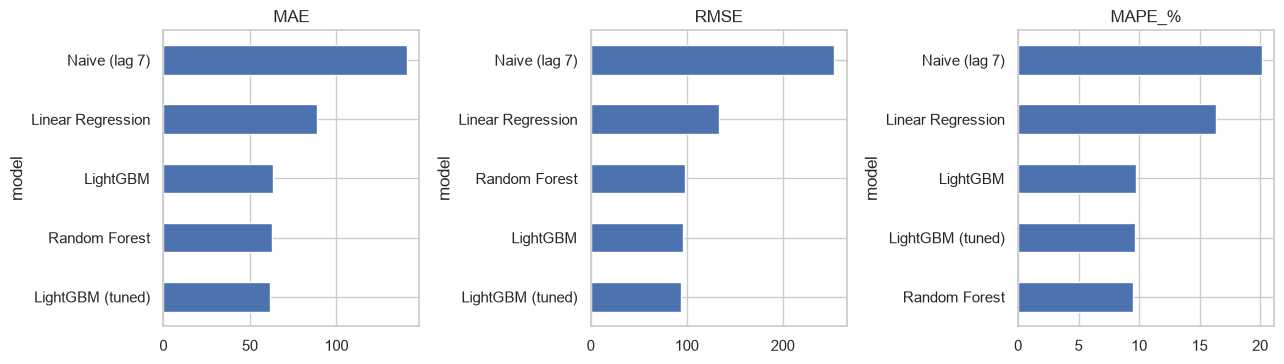

In [48]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, metric in zip(ax, ["MAE", "RMSE", "MAPE_%"]):
    results_df.set_index("model")[metric].sort_values().plot.barh(ax=a, title=metric)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "model_comparison.png", dpi=150)
plt.show()

In [49]:
# Differenced-target models: predict the day-on-day CHANGE, then add it back to yesterday's volume.
# This applies the guide's "difference if non-stationary" step. Compared with the level models.
print("SKUs with a stationary level series:", int(adf_table["level_stationary"].sum()), "of", len(adf_table))

lgb_diff_params = dict(search.best_params_, subsample_freq=1, importance_type="gain",
                       random_state=config.RANDOM_STATE, verbose=-1)
y_tr_d = train["volume"] - train["lag_1"]

m_d = LGBMRegressor(**lgb_diff_params).fit(X_tr, y_tr_d)
lr_d = models_mod.get_models()["Linear Regression"].fit(X_tr_s, y_tr_d)

preds["LightGBM (differenced)"] = np.clip(test["lag_1"].values + m_d.predict(X_te), 0, None)
preds["Linear Regression (differenced)"] = np.clip(test["lag_1"].values + lr_d.predict(X_te_s), 0, None)

diff_rows = [{"model": "LightGBM (tuned, levels)", **evaluate.regression_metrics(y_te, preds["LightGBM (tuned)"])},
             {"model": "LightGBM (differenced)", **evaluate.regression_metrics(y_te, preds["LightGBM (differenced)"])},
             {"model": "Linear Regression (levels)", **evaluate.regression_metrics(y_te, preds["Linear Regression"])},
             {"model": "Linear Regression (differenced)", **evaluate.regression_metrics(y_te, preds["Linear Regression (differenced)"])}]
diff_results = pd.DataFrame(diff_rows).set_index("model")
diff_results.to_csv(config.OUT_DIR / "differencing_comparison.csv")
better = diff_results.loc["LightGBM (differenced)", "MAE"] < diff_results.loc["LightGBM (tuned, levels)", "MAE"]
print("Decision:", "differencing improves LightGBM, use the differenced model" if better
      else "differencing does not improve LightGBM; the lag features already carry the differenced signal, so the level model is kept")
diff_results.round(2)

SKUs with a stationary level series: 9 of 10
Decision: differencing does not improve LightGBM; the lag features already carry the differenced signal, so the level model is kept


,MAE,RMSE,MAPE_%,WAPE_%,Bias_%
model,,,,,
"LightGBM (tuned, levels)",61.730,93.900,9.630,9.310,0.090
LightGBM (differenced),65.890,98.000,10.580,9.940,0.090
Linear Regression (levels),88.960,133.200,16.350,13.410,0.440
Linear Regression (differenced),88.960,133.200,16.350,13.410,0.440


In [50]:
# Accuracy for each of the selected SKUs (best model)
sku_perf = evaluate.group_metrics(preds, "volume", best_name, "sku")
sku_perf = sku_perf.merge(sel[["sku", "sku_name", "segment"]], on="sku").sort_values("segment")
sku_perf.round(2)

,sku,MAE,RMSE,MAPE_%,WAPE_%,Bias_%,sku_name,segment
8,SKU0092,76.830,96.000,9.770,9.460,1.470,BrandB Soap,AX
9,SKU0100,69.610,89.020,8.540,8.320,0.610,BrandD Toothpaste,AX
2,SKU0026,87.830,108.970,10.450,10.310,0.210,BrandB Chips,AY
3,SKU0027,108.410,155.380,9.450,9.280,-0.150,BrandC Chips,AY
7,SKU0090,17.730,22.940,9.550,9.300,0.240,BrandF Shampoo,BX
5,SKU0046,98.350,129.350,9.400,9.350,-1.840,BrandD Nuts,BY
6,SKU0066,33.270,49.540,9.090,8.890,-0.300,BrandF Cheese,BY
4,SKU0040,22.970,31.000,9.950,9.730,-1.030,BrandD Biscuits,CY
0,SKU0015,15.240,19.940,10.820,10.440,3.080,BrandC Water,CZ
1,SKU0022,87.020,118.110,9.310,9.030,0.690,BrandD Energy drink,CZ


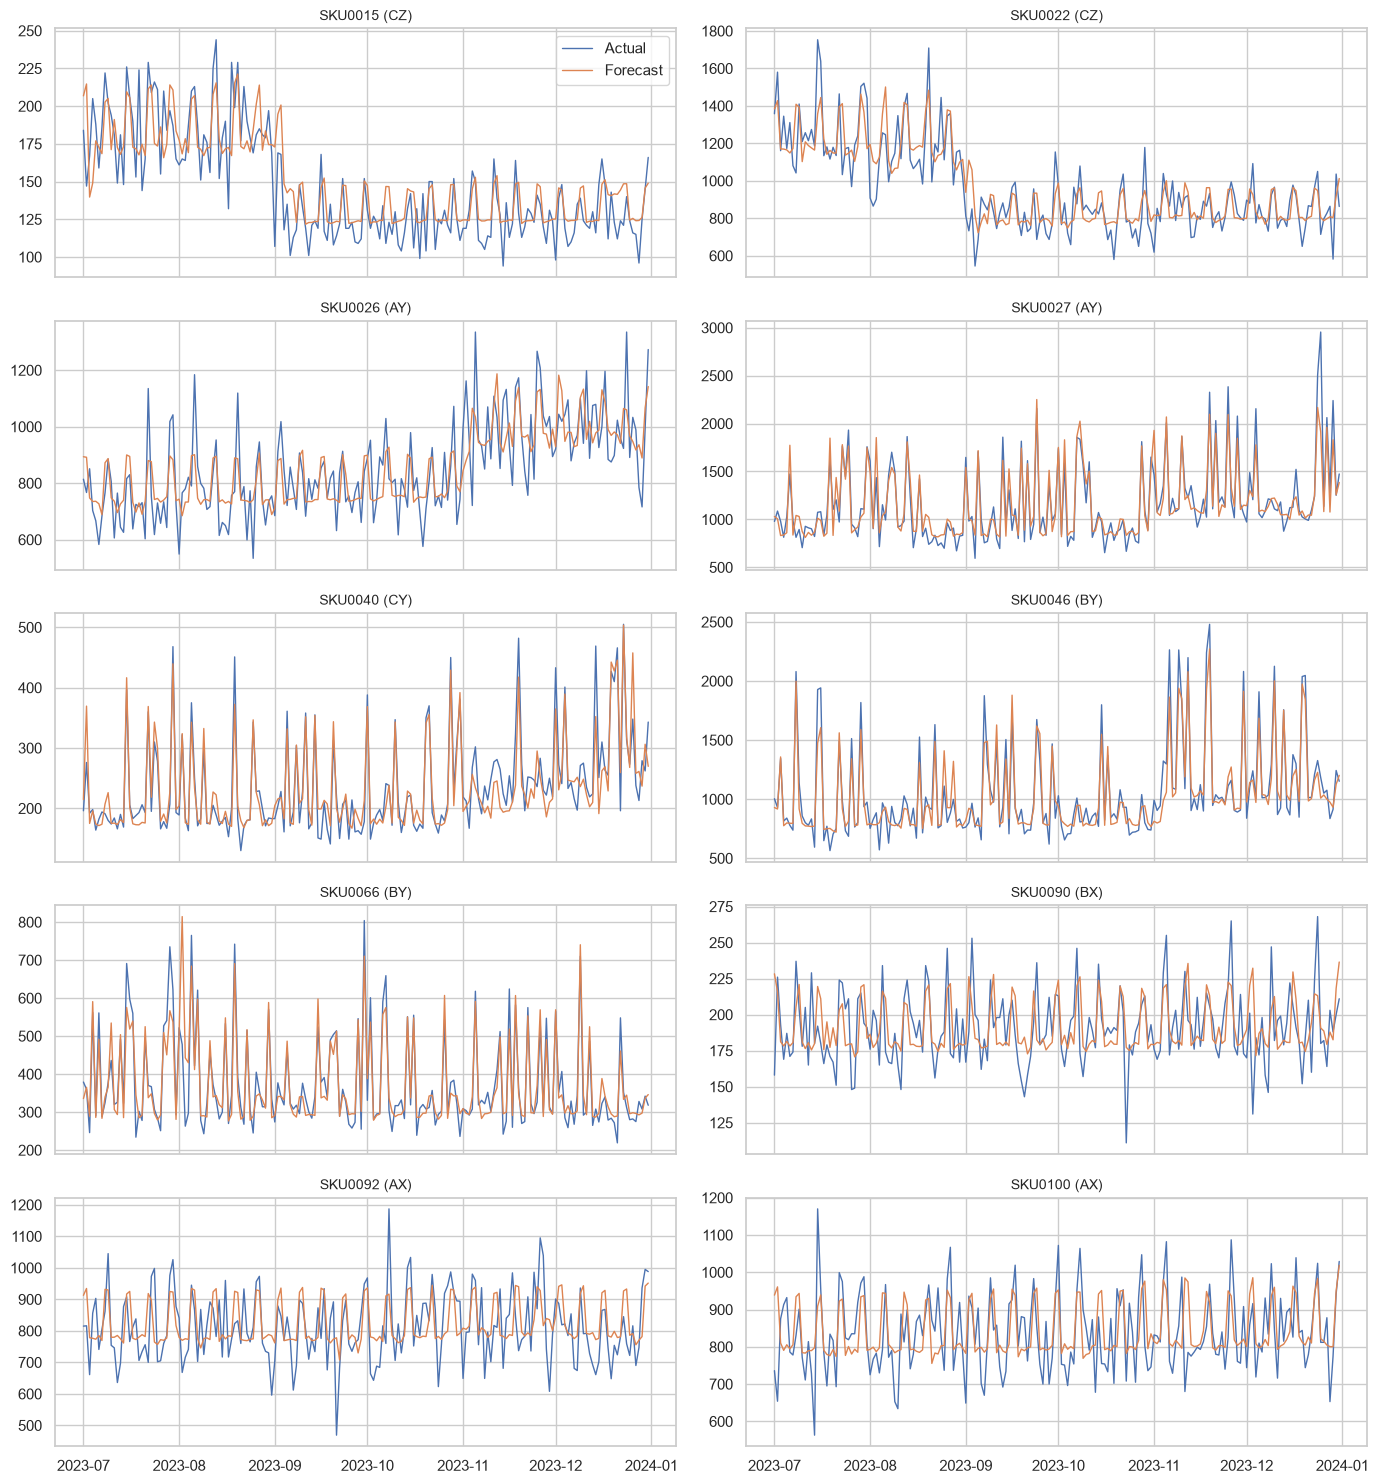

In [51]:
# Forecast vs actual on the hold-out period, all selected SKUs
n = preds["sku"].nunique()
nrows = int(np.ceil(n / 2))
fig, axes = plt.subplots(nrows, 2, figsize=(14, 3 * nrows), sharex=True)
axes = axes.ravel()
for ax, (sku, g) in zip(axes, preds.groupby("sku")):
    seg_name = sel.loc[sel["sku"] == sku, "segment"].iloc[0]
    ax.plot(g["date"], g["volume"], label="Actual", lw=1)
    ax.plot(g["date"], g[best_name], label="Forecast", lw=1)
    ax.set_title(f"{sku} ({seg_name})", fontsize=10)
for ax in axes[n:]:
    ax.axis("off")
axes[0].legend()
plt.tight_layout()
plt.savefig(config.FIG_DIR / "forecast_vs_actual.png", dpi=150)
plt.show()

In [52]:
# Business translation: safety stock = z * forecast-error std * sqrt(lead time), naive vs best model
lt = df[df["sku"].isin(sel_skus)].groupby("sku")["lead_time"].mean()
err = preds.assign(e_model=preds["volume"] - preds[best_name],
                   e_naive=preds["volume"] - preds["Naive (lag 7)"])
ss = err.groupby("sku").agg(avg_daily_units=("volume", "mean"),
                            sigma_naive=("e_naive", "std"), sigma_model=("e_model", "std"))
ss["lead_time_days"] = lt
ss["SS_naive"] = config.SERVICE_Z * ss["sigma_naive"] * np.sqrt(ss["lead_time_days"])
ss["SS_model"] = config.SERVICE_Z * ss["sigma_model"] * np.sqrt(ss["lead_time_days"])
ss["reduction_%"] = (1 - ss["SS_model"] / ss["SS_naive"]) * 100
ss_total_reduction = (1 - ss["SS_model"].sum() / ss["SS_naive"].sum()) * 100
print(f"Total safety stock reduction at 95% service level: {ss_total_reduction:.1f}%")
ss.round(1)

Total safety stock reduction at 95% service level: 57.7%


,avg_daily_units,sigma_naive,sigma_model,lead_time_days,SS_naive,SS_model,reduction_%
sku,,,,,,,
SKU0015,145.900,26.800,19.500,6.500,112.700,81.900,27.300
SKU0022,963.200,184.000,118.200,6.500,774.700,497.900,35.700
SKU0026,851.900,146.500,109.200,6.500,617.100,460.300,25.400
SKU0027,"1,168.700",522.200,155.800,6.500,"2,199.100",656.100,70.200
SKU0040,236.000,99.400,31.000,6.500,418.600,130.500,68.800
SKU0046,"1,051.600",495.100,128.200,6.500,"2,082.800",539.500,74.100
SKU0066,374.400,170.800,49.700,6.500,718.800,209.000,70.900
SKU0090,190.700,32.600,23.000,6.500,137.100,96.900,29.300
SKU0092,812.000,133.900,95.500,6.500,563.500,401.800,28.700


### Stockout prediction (classification)

Target: `stockout` (store-SKU-day). Features use only information available the day before (lagged stock on hand, lagged sales) plus planned items (promo, price, calendar, lead time). Same-day stock on hand is excluded because it would leak the answer. Geography (country, city) is label-encoded; channel and SKU are one-hot encoded.

In [53]:
# Row-level frame with lagged stock signals, split in time at the same cutoff
from sklearn.preprocessing import LabelEncoder, StandardScaler

so = features.build_stockout_frame(df, sel_skus)
so["country_code"] = LabelEncoder().fit_transform(so["country"])
so["city_code"] = LabelEncoder().fit_transform(so["city"])

num = ["price", "discount", "promo", "lead_time", "month", "dow", "is_holiday", "is_weekend",
       "soh_lag1", "units_lag1", "units_roll7", "stockout_lag1", "cover_days_lag1",
       "country_code", "city_code"]
Xc = pd.get_dummies(so[num + ["channel", "sku"]], columns=["channel", "sku"], dtype=int)
Xc.columns = models_mod._clean_cols(Xc.columns)
yc = so["stockout"]

is_train = (so["date"] <= cutoff).values
Xc_tr, Xc_te, yc_tr, yc_te = Xc[is_train], Xc[~is_train], yc[is_train], yc[~is_train]
print(f"Stockout rate train / test: {yc_tr.mean():.3%} / {yc_te.mean():.3%} | rows {len(Xc_tr):,} / {len(Xc_te):,}")
assert yc_tr.sum() > 0 and yc_te.sum() > 0, "no stockouts in train or test for the selected SKUs"

Stockout rate train / test: 2.971% / 3.071% | rows 93,112 / 18,952


In [54]:
# Logistic Regression (scaled, train-only scaler) vs LightGBM classifier; both class-balanced
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

sc = StandardScaler().fit(Xc_tr[num])
A, B = Xc_tr.copy(), Xc_te.copy()
A[num], B[num] = sc.transform(Xc_tr[num]), sc.transform(Xc_te[num])

logit = LogisticRegression(max_iter=1000, class_weight="balanced").fit(A, yc_tr)
clf = LGBMClassifier(n_estimators=400, learning_rate=0.05, class_weight="balanced",
                     random_state=config.RANDOM_STATE, verbose=-1).fit(Xc_tr, yc_tr)

cls_results = pd.DataFrame({
    "Logistic Regression": evaluate.classification_summary(yc_te, logit.predict(B), logit.predict_proba(B)[:, 1]),
    "LightGBM": evaluate.classification_summary(yc_te, clf.predict(Xc_te), clf.predict_proba(Xc_te)[:, 1]),
}).T
cls_results.round(3)

,Precision,Recall,F1,PR_AUC,ROC_AUC
Logistic Regression,0.032,0.543,0.060,0.033,0.510
LightGBM,0.033,0.227,0.058,0.033,0.522


              precision    recall  f1-score   support

           0      0.970     0.790     0.871     18370
           1      0.033     0.227     0.058       582

    accuracy                          0.772     18952
   macro avg      0.501     0.508     0.464     18952
weighted avg      0.941     0.772     0.846     18952



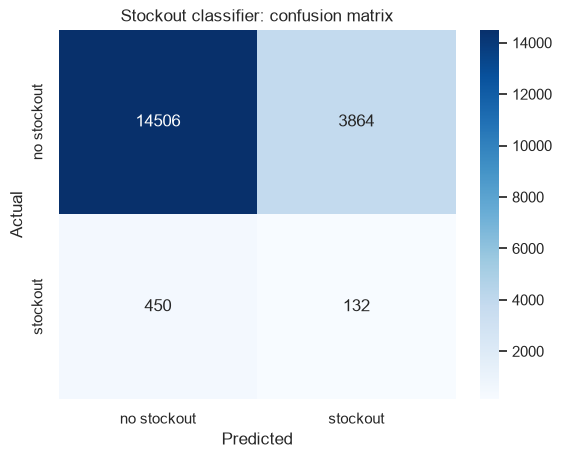

In [55]:
# Detail for the LightGBM classifier: report and confusion matrix
from sklearn.metrics import classification_report, confusion_matrix

pred_c = clf.predict(Xc_te)
print(classification_report(yc_te, pred_c, digits=3))
sns.heatmap(confusion_matrix(yc_te, pred_c), annot=True, fmt="d", cmap="Blues",
            xticklabels=["no stockout", "stockout"], yticklabels=["no stockout", "stockout"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Stockout classifier: confusion matrix")
plt.savefig(config.FIG_DIR / "stockout_confusion.png", dpi=150)
plt.show()

## Step 6: Explainability, ethics and impact

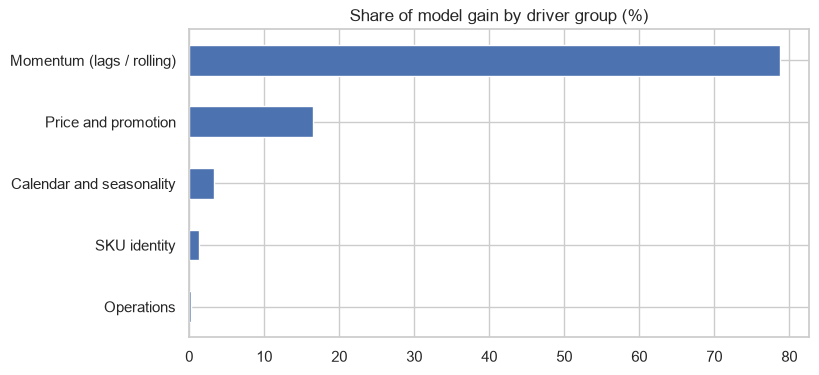

,gain
roll_mean_7,"4,595,899,781.000"
lag_30,"1,238,271,743.000"
lag_7,"939,217,054.000"
discount,"882,699,981.000"
lag_1,"797,159,608.000"
promo,"481,287,962.000"
price_change,"127,290,810.000"
dow,"122,156,470.000"
price,"97,740,076.000"
is_weekend,"82,515,641.000"


In [56]:
# Feature importance grouped by driver: does the model lean on momentum (lags) or on promotions/price?
imp = pd.Series(fitted["LightGBM (tuned)"].feature_importances_, index=X_tr.columns)

def group_of(f):
    if f.startswith(("lag_", "roll_")): return "Momentum (lags / rolling)"
    if f in ("price", "price_change", "discount", "promo"): return "Price and promotion"
    if f in ("lead_time_lag1", "stockout_lag1"): return "Operations"
    if f.startswith("sku_"): return "SKU identity"
    return "Calendar and seasonality"

grouped = (imp.groupby(imp.index.map(group_of)).sum() / imp.sum() * 100).sort_values()
grouped.plot.barh(title="Share of model gain by driver group (%)", figsize=(8, 4))
plt.savefig(config.FIG_DIR / "importance_groups.png", dpi=150, bbox_inches="tight")
plt.show()
imp.sort_values(ascending=False).head(10).to_frame("gain").round(0)

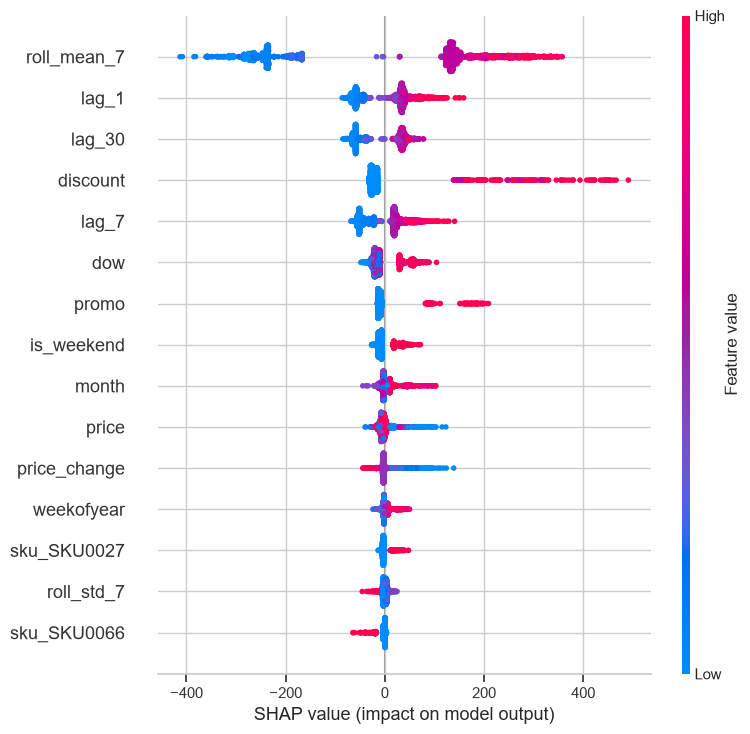

In [57]:
# SHAP: direction and size of each feature's effect on the forecast
import shap

sample_x = X_te.sample(min(2000, len(X_te)), random_state=config.RANDOM_STATE)
sv = shap.TreeExplainer(fitted["LightGBM (tuned)"]).shap_values(sample_x)
shap.summary_plot(sv, sample_x, show=False, max_display=15)
plt.savefig(config.FIG_DIR / "shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [58]:
# Bias audit: build a SKU x channel panel and find the small-format / local-retailer channel
small, why = segmentation.pick_small_format_channels(df)
print("Small-format channel(s):", small, "|", why)
print("All channels:", sorted(df["channel"].unique()))

panel_ch = features.add_features(features.build_panel(df, sel_skus, by_channel=True))
tr_c, te_c, _ = features.time_split(panel_ch)
Xtr_c, Xte_c, *_ = models_mod.make_matrices(tr_c, te_c, features.NUM_FEATURES, ["sku", "channel"])
print(Xtr_c.shape, Xte_c.shape)

Small-format channel(s): ['Convenience'] | name matches a small-format keyword
All channels: ['Convenience', 'E-commerce', 'Hypermarket', 'Supermarket']
(30835, 32) (6440, 32)


In [59]:
# Train the channel-aware model and measure bias per channel (Bias_% < 0 = systematic under-forecast = under-allocation)
lgb_params = dict(search.best_params_, subsample_freq=1, importance_type="gain",
                  random_state=config.RANDOM_STATE, verbose=-1)
m_c = LGBMRegressor(**lgb_params).fit(Xtr_c, tr_c["volume"])
te_c = te_c.assign(pred=np.clip(m_c.predict(Xte_c), 0, None))

bias = evaluate.group_metrics(te_c, "volume", "pred", "channel").set_index("channel")
active = te_c[te_c["volume"] > 0]
bias["under_forecast_days_%"] = (active["pred"] < active["volume"]).groupby(active["channel"]).mean() * 100
bias.round(2)

,MAE,RMSE,MAPE_%,WAPE_%,Bias_%,under_forecast_days_%
channel,,,,,,
Convenience,8.620,14.130,51.480,28.360,3.160,44.430
E-commerce,27.400,42.410,31.960,19.880,-0.070,49.430
Hypermarket,50.280,74.110,14.170,13.530,-0.120,50.710
Supermarket,23.980,35.970,21.060,17.320,0.310,47.930


In [60]:
# Mitigation: give the small-format channel double weight in training, then re-audit
w = np.where(tr_c["channel"].isin(small), 2.0, 1.0)
m_w = LGBMRegressor(**lgb_params).fit(Xtr_c, tr_c["volume"], sample_weight=w)
te_c["pred_weighted"] = np.clip(m_w.predict(Xte_c), 0, None)

compare = pd.concat([
    evaluate.group_metrics(te_c, "volume", "pred", "channel").assign(version="baseline"),
    evaluate.group_metrics(te_c, "volume", "pred_weighted", "channel").assign(version="weighted")])
compare[["channel", "version", "WAPE_%", "Bias_%"]].sort_values(["channel", "version"]).round(2)

,channel,version,WAPE_%,Bias_%
0,Convenience,baseline,28.360,3.160
0,Convenience,weighted,27.660,1.360
1,E-commerce,baseline,19.880,-0.070
1,E-commerce,weighted,19.860,0.060
2,Hypermarket,baseline,13.530,-0.120
2,Hypermarket,weighted,13.620,-0.060
3,Supermarket,baseline,17.320,0.310
3,Supermarket,weighted,17.340,0.450


In [61]:
# Plain-English bias findings (numbers for the slides and the ethics section)
b0 = bias.loc[small, "Bias_%"].mean()
b_others = bias.drop(index=small)["Bias_%"].mean()
bw = evaluate.group_metrics(te_c[te_c["channel"].isin(small)], "volume", "pred_weighted", "channel")["Bias_%"].mean()
print(f"Small-format channel(s) {small}: bias {b0:+.2f}% vs {b_others:+.2f}% for the other channels")
print(f"After re-weighting, small-format bias: {bw:+.2f}%")
print("Interpretation:", "the baseline model under-forecasts local retailers relative to others (allocation risk)"
      if b0 < b_others - 1 else "no material systematic under-allocation of the small-format channel was found")

Small-format channel(s) ['Convenience']: bias +3.16% vs +0.04% for the other channels
After re-weighting, small-format bias: +1.36%
Interpretation: no material systematic under-allocation of the small-format channel was found


### Ethical considerations (African context)

- **Why it matters.** In many African markets Traditional Trade (kiosks, dukas) is the main route to food and essential goods. A stockout there is a food-security issue for the community, not only lost revenue.
- **Bias risk.** A model trained on pooled data is dominated by high-volume channels (Modern Trade, E-commerce). Errors that systematically under-forecast small-format channels lead to under-allocation of stock to them.
- **What we did.** We audited signed bias (Bias_%) and the share of under-forecast days per channel, and tested a mitigation (higher training weight for the small-format channel). The numbers are in the cells above.
- **Governance.** Monitor signed bias per channel monthly, keep a human planner in the S&OP loop with authority to override, and never optimise forecast accuracy alone: track the service level of the smallest outlets too.
- **Limits.** This dataset's channels may not include Traditional Trade by that name; the audit applies to whichever channel is smallest-format in the data.

In [62]:
# Headline results for the README and the slides
headline = pd.Series({
    "Rows analysed": f"{len(df):,}",
    "A-SKUs share of revenue": f"{summary.loc['A', 'revenue_share']:.0%} from {int(summary.loc['A', 'n_skus'])} SKUs",
    "Promo lift (raw units)": f"{lift_raw:+.1f}%",
    "Promo lift (baseline-adjusted)": f"{lift_adj:+.1f}%",
    "Median price elasticity (A-SKUs)": f"{elas['elasticity_total'].median():.2f}",
    "Best forecast model": best_name,
    "WAPE naive -> best": f"{naive_wape:.1f}% -> {ml_only.iloc[0]['WAPE_%']:.1f}%",
    "MAE / RMSE / MAPE (best)": f"{ml_only.iloc[0]['MAE']:.1f} / {ml_only.iloc[0]['RMSE']:.1f} / {ml_only.iloc[0]['MAPE_%']:.1f}%",
    "Safety stock reduction vs naive": f"{ss_total_reduction:.1f}%",
    "Stockout classifier (LightGBM) recall / precision": f"{cls_results.loc['LightGBM', 'Recall']:.2f} / {cls_results.loc['LightGBM', 'Precision']:.2f}",
}, name="headline")
headline.to_frame()

,headline
Rows analysed,"1,100,000"
A-SKUs share of revenue,80% from 50 SKUs
Promo lift (raw units),+88.7%
Promo lift (baseline-adjusted),+67.6%
Median price elasticity (A-SKUs),-2.54
Best forecast model,LightGBM (tuned)
WAPE naive -> best,21.2% -> 9.3%
MAE / RMSE / MAPE (best),61.7 / 93.9 / 9.6%
Safety stock reduction vs naive,57.7%
Stockout classifier (LightGBM) recall / precision,0.23 / 0.03


In [63]:
# Save every result table for the repo and the slides
out = config.OUT_DIR
results_df.to_csv(out / "model_comparison.csv", index=False)
sku_perf.to_csv(out / "sku_performance.csv", index=False)
bias.to_csv(out / "channel_bias.csv")
compare.to_csv(out / "channel_bias_mitigation.csv", index=False)
seg.to_csv(out / "abc_xyz_segments.csv", index=False)
elas.to_csv(out / "elasticity_a_skus.csv", index=False)
ss.to_csv(out / "safety_stock.csv")
cls_results.to_csv(out / "stockout_classifier.csv")
promo_results.to_csv(out / "promo_tests.csv")
headline.to_csv(out / "headline.csv")
print("Saved:", sorted(p.name for p in out.glob("*.csv")))

Saved: ['abc_xyz_segments.csv', 'channel_bias.csv', 'channel_bias_mitigation.csv', 'differencing_comparison.csv', 'elasticity_a_skus.csv', 'headline.csv', 'model_comparison.csv', 'promo_tests.csv', 'safety_stock.csv', 'sku_performance.csv', 'stockout_classifier.csv']


### Recommendations

1. **S&OP visibility.** Run one weekly forecast across all countries, segmented by ABC/XYZ, and review A-products first.
2. **Safety stock.** Set it per segment from forecast error and lead-time variability (see the safety-stock table): lean for stable AX items, minimal or make-to-order for CZ items.
3. **Logistics deserts.** Add buffer stock or alternate lanes where high demand meets high lead-time variability (see the city map and table).
4. **Promotions.** Plan inventory with the measured lift, not the baseline, and keep promo calendars in the forecast as a feature.
5. **Bullwhip and risk pooling.** Forecast from end-consumer sales signals rather than downstream orders, and hold pooled safety stock where variability is lowest (higher echelons).
6. **Equity.** Monitor signed forecast bias for small-format outlets monthly and keep the re-weighting safeguard, so local retailers are not under-supplied.

## Step 7: Financial impact and scale

Turns forecast accuracy into money, tests whether promotions are actually profitable, scales the model to all A-SKUs, and checks whether the stockout flag is explainable by stock levels. Unit cost comes from `purchase_cost`; the dataset does not state a currency, so values are in money units.

In [64]:
# Pull unit purchase cost from the database and compute gross profit per row
cost = data_prep.run_query(f'''
    SELECT "date", "store_id" AS store, "sku_id" AS sku, "purchase_cost" AS unit_cost
    FROM {config.TABLE}''')
cost["date"] = pd.to_datetime(cost["date"])
df = (df.drop(columns=["unit_cost", "gross_profit"], errors="ignore")
        .merge(cost, on=["date", "store", "sku"], how="left"))
df["gross_profit"] = df["revenue"] - df["volume"] * df["unit_cost"]
del cost
print(f"Missing unit cost: {df['unit_cost'].isna().sum()} | overall gross margin: {df['gross_profit'].sum() / df['revenue'].sum():.1%}")

Missing unit cost: 0 | overall gross margin: 38.5%


In [65]:
# Are promotions profitable? Units and gross profit vs each store-SKU's own non-promo baseline, by discount depth
base = (df[df["promo"] == 0].groupby(["store", "sku"])[["volume", "gross_profit"]].mean()
          .rename(columns={"volume": "base_units", "gross_profit": "base_profit"}))
tmp = df[["store", "sku", "discount", "promo", "volume", "gross_profit"]].join(base, on=["store", "sku"])
tmp["level"] = np.where(tmp["promo"] == 0, "no promo",
                        (tmp["discount"] * 100).round().astype(int).astype(str) + "% off")

promo_profit = tmp.groupby("level").agg(rows=("volume", "size"), units=("volume", "sum"),
                                        base_units=("base_units", "sum"), profit=("gross_profit", "sum"),
                                        base_profit=("base_profit", "sum"))
promo_profit["units_lift_%"] = (promo_profit["units"] / promo_profit["base_units"] - 1) * 100
promo_profit["profit_lift_%"] = (promo_profit["profit"] / promo_profit["base_profit"] - 1) * 100
promo_profit["profit_per_unit"] = promo_profit["profit"] / promo_profit["units"]
del tmp
promo_profit[["rows", "units_lift_%", "profit_lift_%", "profit_per_unit"]].round(2)

,rows,units_lift_%,profit_lift_%,profit_per_unit
level,,,,
10% off,22274,68.480,26.450,1.940
15% off,22367,78.930,11.560,1.690
20% off,22086,89.100,-5.690,1.330
30% off,21530,109.490,-48.170,0.670
no promo,1011743,0.000,0.000,3.030


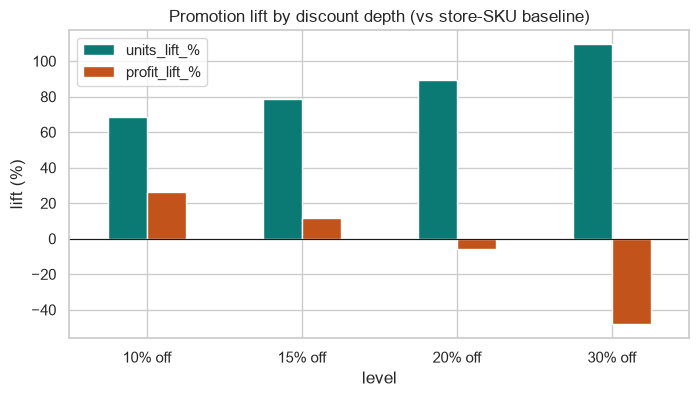

Most profitable depth: 10% off | depths that LOSE profit vs baseline: ['20% off', '30% off']


In [66]:
# Chart: volume lift vs profit lift by discount depth
pp = promo_profit.drop(index="no promo")
pp[["units_lift_%", "profit_lift_%"]].plot.bar(rot=0, figsize=(8, 4), color=["#0B7A75", "#C2531B"],
                                                title="Promotion lift by discount depth (vs store-SKU baseline)")
plt.axhline(0, c="k", lw=0.8); plt.ylabel("lift (%)")
plt.savefig(config.FIG_DIR / "promo_profit_by_discount.png", dpi=150, bbox_inches="tight")
plt.show()
best_depth = pp["profit_lift_%"].idxmax()
print(f"Most profitable depth: {best_depth} | depths that LOSE profit vs baseline: "
      f"{list(pp.index[pp['profit_lift_%'] < 0]) or 'none'}")

In [67]:
# Scale 1: the same pipeline on ALL A-SKUs (hold-out = last 6 months), compared with the naive forecast
a_skus = abc.loc[abc["abc"] == "A", "sku"].tolist()
panel_a = features.add_features(features.build_panel(df, a_skus))
tr_a, te_a, _ = features.time_split(panel_a)
Xa_tr, Xa_te, *_ = models_mod.make_matrices(tr_a, te_a, features.NUM_FEATURES, ["sku"])

m_a = LGBMRegressor(**lgb_params).fit(Xa_tr, tr_a["volume"])
te_a = te_a.assign(pred=np.clip(m_a.predict(Xa_te), 0, None), naive=te_a["lag_7"].values,
                   segment=te_a["sku"].map(seg.set_index("sku")["segment"]))
scale_overall = pd.DataFrame({"LightGBM": evaluate.regression_metrics(te_a["volume"], te_a["pred"]),
                              "Naive (lag 7)": evaluate.regression_metrics(te_a["volume"], te_a["naive"])}).T
print(f"{len(a_skus)} A-SKUs | train {len(tr_a):,} rows | test {len(te_a):,} rows")
scale_overall.round(2)

50 A-SKUs | train 44,050 rows | test 9,200 rows


,MAE,RMSE,MAPE_%,WAPE_%,Bias_%
LightGBM,72.040,101.980,10.200,9.840,0.170
Naive (lag 7),159.100,283.000,20.510,21.730,-0.080


In [68]:
# Accuracy by ABC/XYZ segment across all A-SKUs
acc_seg = pd.concat([
    evaluate.group_metrics(te_a, "volume", "pred", "segment")[["segment", "WAPE_%", "Bias_%"]].set_index("segment").add_suffix("_model"),
    evaluate.group_metrics(te_a, "volume", "naive", "segment")[["segment", "WAPE_%"]].set_index("segment").add_suffix("_naive")], axis=1)
acc_seg["n_skus"] = te_a.groupby("segment")["sku"].nunique()
acc_seg.round(2)

,WAPE_%_model,Bias_%_model,WAPE_%_naive,n_skus
segment,,,,
AX,9.250,0.090,12.430,18
AY,10.040,0.200,25.520,16
AZ,10.140,0.220,25.930,16


In [69]:
# Scale 2: accuracy by channel for all A-SKUs (SKU x channel panel)
panel_ac = features.add_features(features.build_panel(df, a_skus, by_channel=True))
tr_ac, te_ac, _ = features.time_split(panel_ac)
Xac_tr, Xac_te, *_ = models_mod.make_matrices(tr_ac, te_ac, features.NUM_FEATURES, ["sku", "channel"])
m_ac = LGBMRegressor(**lgb_params).fit(Xac_tr, tr_ac["volume"])
te_ac = te_ac.assign(pred=np.clip(m_ac.predict(Xac_te), 0, None), naive=te_ac["lag_7"].values)

acc_channel = pd.concat([
    evaluate.group_metrics(te_ac, "volume", "pred", "channel")[["channel", "WAPE_%", "Bias_%"]].set_index("channel").add_suffix("_model"),
    evaluate.group_metrics(te_ac, "volume", "naive", "channel")[["channel", "WAPE_%"]].set_index("channel").add_suffix("_naive")], axis=1)
acc_channel.round(2)

,WAPE_%_model,Bias_%_model,WAPE_%_naive
channel,,,
Convenience,28.740,2.720,44.340
E-commerce,18.330,-0.070,30.890
Hypermarket,13.610,0.210,25.700
Supermarket,19.130,0.240,31.710


In [70]:
# Scale 3: accuracy by COUNTRY for all A-SKUs (build_panel groups by a "channel" column, so country is passed in that slot)
slim = df[["date", "sku", "country", "volume", "revenue", "promo", "discount",
           "lead_time", "stockout", "is_holiday"]].rename(columns={"country": "channel"})
panel_co = features.add_features(features.build_panel(slim, a_skus, by_channel=True))
del slim
tr_co, te_co, _ = features.time_split(panel_co)
Xco_tr, Xco_te, *_ = models_mod.make_matrices(tr_co, te_co, features.NUM_FEATURES, ["sku", "channel"])
m_co = LGBMRegressor(**lgb_params).fit(Xco_tr, tr_co["volume"])
te_co = te_co.assign(pred=np.clip(m_co.predict(Xco_te), 0, None), naive=te_co["lag_7"].values)

acc_country = pd.concat([
    evaluate.group_metrics(te_co, "volume", "pred", "channel")[["channel", "WAPE_%", "Bias_%"]].set_index("channel").add_suffix("_model"),
    evaluate.group_metrics(te_co, "volume", "naive", "channel")[["channel", "WAPE_%"]].set_index("channel").add_suffix("_naive")], axis=1)
acc_country.index.name = "country"
acc_country.to_csv(config.OUT_DIR / "a_sku_accuracy_by_country.csv")
acc_country.sort_values("WAPE_%_model").round(2)

,WAPE_%_model,Bias_%_model,WAPE_%_naive
country,,,
Italy,16.690,-0.180,29.720
Spain,18.360,-0.270,30.900
Germany,21.970,-0.350,35.130
France,27.870,0.730,43.310
Poland,28.380,1.020,43.850
Austria,28.510,1.360,43.390
Netherlands,28.650,2.870,44.340


In [71]:
# Cash tied up in safety stock for all A-SKUs: naive vs model.
# SS = z * forecast-error std * sqrt(lead time), valued at unit purchase cost (network-level, in units then money).
CARRY_RATE = 0.25   # assumption: annual inventory carrying cost = 25% of stock value

w = df[df["sku"].isin(a_skus)].assign(c=lambda t: t["volume"] * t["unit_cost"]).groupby("sku")[["c", "volume"]].sum()
unit_cost = (w["c"] / w["volume"]).rename("unit_cost")
lt_a = df[df["sku"].isin(a_skus)].groupby("sku")["lead_time"].mean().rename("lead_time_days")

e = te_a.assign(e_model=te_a["volume"] - te_a["pred"], e_naive=te_a["volume"] - te_a["naive"])
fin = (e.groupby("sku").agg(sigma_model=("e_model", "std"), sigma_naive=("e_naive", "std"))
         .join(unit_cost).join(lt_a))
for k in ("naive", "model"):
    fin[f"SS_units_{k}"] = config.SERVICE_Z * fin[f"sigma_{k}"] * np.sqrt(fin["lead_time_days"])
    fin[f"SS_value_{k}"] = fin[f"SS_units_{k}"] * fin["unit_cost"]
fin["cash_freed"] = fin["SS_value_naive"] - fin["SS_value_model"]

freed, naive_val = fin["cash_freed"].sum(), fin["SS_value_naive"].sum()
rev_year = df[df["sku"].isin(a_skus)]["revenue"].sum() / 3
print(f"Safety stock value: naive {naive_val:,.0f} -> model {fin['SS_value_model'].sum():,.0f}")
print(f"Cash freed: {freed:,.0f} ({freed / naive_val:.1%}) | carrying-cost saving at {CARRY_RATE:.0%}/yr: {freed * CARRY_RATE:,.0f}")
print(f"For scale: A-SKU revenue per year = {rev_year:,.0f}")
fin.sort_values("cash_freed", ascending=False).head(10).round(1)

Safety stock value: naive 259,924 -> model 116,709
Cash freed: 143,215 (55.1%) | carrying-cost saving at 25%/yr: 35,804
For scale: A-SKU revenue per year = 126,225,865


,sigma_model,sigma_naive,unit_cost,lead_time_days,SS_units_naive,SS_value_naive,SS_units_model,SS_value_model,cash_freed
sku,,,,,,,,,
SKU0027,156.700,522.200,8.500,6.500,"2,199.100","18,684.100",659.700,"5,605.300","13,078.800"
SKU0099,122.400,550.200,6.700,6.500,"2,314.800","15,502.000",515.200,"3,450.000","12,052.000"
SKU0001,230.200,860.100,3.800,6.500,"3,625.300","13,595.100",970.500,"3,639.500","9,955.600"
SKU0005,153.500,565.900,5.600,6.500,"2,377.400","13,428.500",644.900,"3,642.600","9,785.900"
SKU0041,122.400,375.600,7.800,6.500,"1,579.200","12,387.200",514.400,"4,034.900","8,352.300"
SKU0045,107.800,343.700,8.000,6.500,"1,443.600","11,610.100",452.500,"3,639.700","7,970.500"
SKU0048,95.400,362.900,7.100,6.500,"1,528.000","10,808.200",401.700,"2,841.100","7,967.100"
SKU0013,144.400,497.300,4.400,6.500,"2,093.100","9,283.000",607.800,"2,695.500","6,587.500"
SKU0079,80.100,277.800,6.200,6.500,"1,166.600","7,278.500",336.100,"2,097.200","5,181.300"


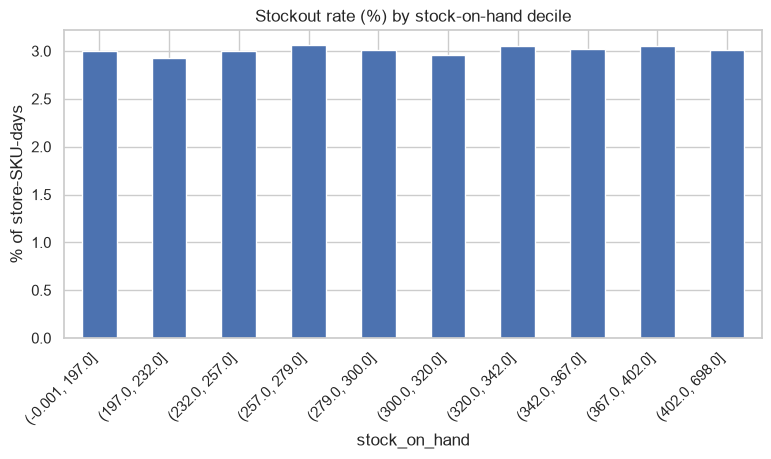

Spearman (stock on hand vs stockout flag): rho = -0.000, p = 0.929


In [72]:
# Stockout diagnosis 1: does the stockout flag line up with the stock on hand?
dec = pd.qcut(df["stock_on_hand"], 10, duplicates="drop")
by_stock = df.groupby(dec, observed=True)["stockout"].mean() * 100
by_stock.index = by_stock.index.astype(str)
by_stock.plot.bar(figsize=(9, 4), title="Stockout rate (%) by stock-on-hand decile", ylabel="% of store-SKU-days")
plt.xticks(rotation=45, ha="right")
plt.savefig(config.FIG_DIR / "stockout_by_stock_decile.png", dpi=150, bbox_inches="tight")
plt.show()
smp = df.sample(min(200_000, len(df)), random_state=config.RANDOM_STATE)
rho_s, p_s = spearmanr(smp["stock_on_hand"], smp["stockout"])
print(f"Spearman (stock on hand vs stockout flag): rho = {rho_s:.3f}, p = {p_s:.3g}")

In [73]:
# Stockout diagnosis 2: do flagged days actually sell less? (units relative to each store-SKU's average)
if "vol_index" not in df.columns:
    df["vol_index"] = df["volume"] / df.groupby(["store", "sku"])["volume"].transform("mean")
so_sales = df.groupby("stockout")["vol_index"].agg(["mean", "count"])
so_sales.index = ["no stockout", "stockout"]
so_effect = (so_sales.loc["stockout", "mean"] / so_sales.loc["no stockout", "mean"] - 1) * 100
print(f"Sales on stockout days vs normal days: {so_effect:+.1f}% (relative units)")
so_sales.round(3)

Sales on stockout days vs normal days: -81.2% (relative units)


,mean,count
no stockout,1.025,1066886
stockout,0.192,33114


In [74]:
# Step 7 summary and saved tables
sc = scale_overall
summary7 = pd.Series({
    "Best promo discount depth (profit)": best_depth,
    "Depths that lose profit": ", ".join(pp.index[pp["profit_lift_%"] < 0]) or "none",
    "A-SKUs modelled": len(a_skus),
    "A-SKU WAPE: naive -> LightGBM": f"{sc.loc['Naive (lag 7)', 'WAPE_%']:.1f}% -> {sc.loc['LightGBM', 'WAPE_%']:.1f}%",
    "A-SKU MAE / MAPE (LightGBM)": f"{sc.loc['LightGBM', 'MAE']:.1f} / {sc.loc['LightGBM', 'MAPE_%']:.1f}%",
    "Safety-stock cash freed": f"{freed:,.0f} ({freed / naive_val:.0%})",
    "Annual carrying-cost saving (25%)": f"{freed * CARRY_RATE:,.0f}",
    "Stock-on-hand vs stockout flag (rho)": f"{rho_s:.3f}",
    "Sales on stockout days vs normal": f"{so_effect:+.1f}%",
}, name="step 7")

out = config.OUT_DIR
promo_profit.to_csv(out / "promo_profit_by_discount.csv")
acc_seg.to_csv(out / "a_sku_accuracy_by_segment.csv")
acc_channel.to_csv(out / "a_sku_accuracy_by_channel.csv")
fin.to_csv(out / "financial_impact_safety_stock.csv")
scale_overall.to_csv(out / "a_sku_accuracy_overall.csv")
summary7.to_csv(out / "step7_summary.csv")
summary7.to_frame()

,step 7
Best promo discount depth (profit),10% off
Depths that lose profit,"20% off, 30% off"
A-SKUs modelled,50
A-SKU WAPE: naive -> LightGBM,21.7% -> 9.8%
A-SKU MAE / MAPE (LightGBM),72.0 / 10.2%
Safety-stock cash freed,"143,215 (55%)"
Annual carrying-cost saving (25%),"35,804"
Stock-on-hand vs stockout flag (rho),-0.000
Sales on stockout days vs normal,-81.2%
